In [1]:
import run_judge
from importlib import reload

/home/jmayer/miniconda3/envs/mlenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2025-09-09 18:02:42,856 INFO: Starting judge processing script.
2025-09-09 18:02:42,858 INFO: No existing results found. Starting fresh.
2025-09-09 18:02:42,861 INFO: Processing region: SEA, 146 files.
2025-09-09 18:02:42,862 INFO: Processing file 2 of 146 in SEA: /home/jmayer/Object_Data/ACM_CAP_2B//2025/05/01/ECA_EXAB_ACM_CAP_2B_20250501T135232Z_20250501T153913Z_05253E.h5
2025-09-09 18:02:42,932 INFO: Loading MCOP: /home/jmayer/Object_Data/MSI_COP_2A//2025/05/01/ECA_EXAB_MSI_COP_2A_20250501T135232Z_20250501T153006Z_05253E.h5
2025-09-09 18:02:42,932 INFO: Loading MRGR: /home/jmayer/Object_Data/MSI_RGR_1C//2025/05/01/ECA_EXBA_MSI_RGR_1C_20250501T135232Z_20250623T083732Z_05253E.h5


Progress: |--------------------------------------------------| 0.7% Complete
Selecting frame from 432 to 11472
Selecting frame from 432 to 11472


2025-09-09 18:02:47,984 INFO: Running judge...


(16, 4, 128, 128) 16


2025-09-09 18:02:49,279 INFO: Judge completed.
2025-09-09 18:02:49,284 INFO: Plotting results...


[4 5 4 5 4 5 4 5 4 4 4 4 4 4 4 4] tensor([0.9892, 0.8892, 0.8215, 0.9364, 0.8753, 0.9144, 0.9752, 0.6599, 0.9486,
        0.9903, 0.9139, 0.9387, 0.9416, 0.9736, 0.8103, 0.9832])
(16,)


TypeError: only length-1 arrays can be converted to Python scalars

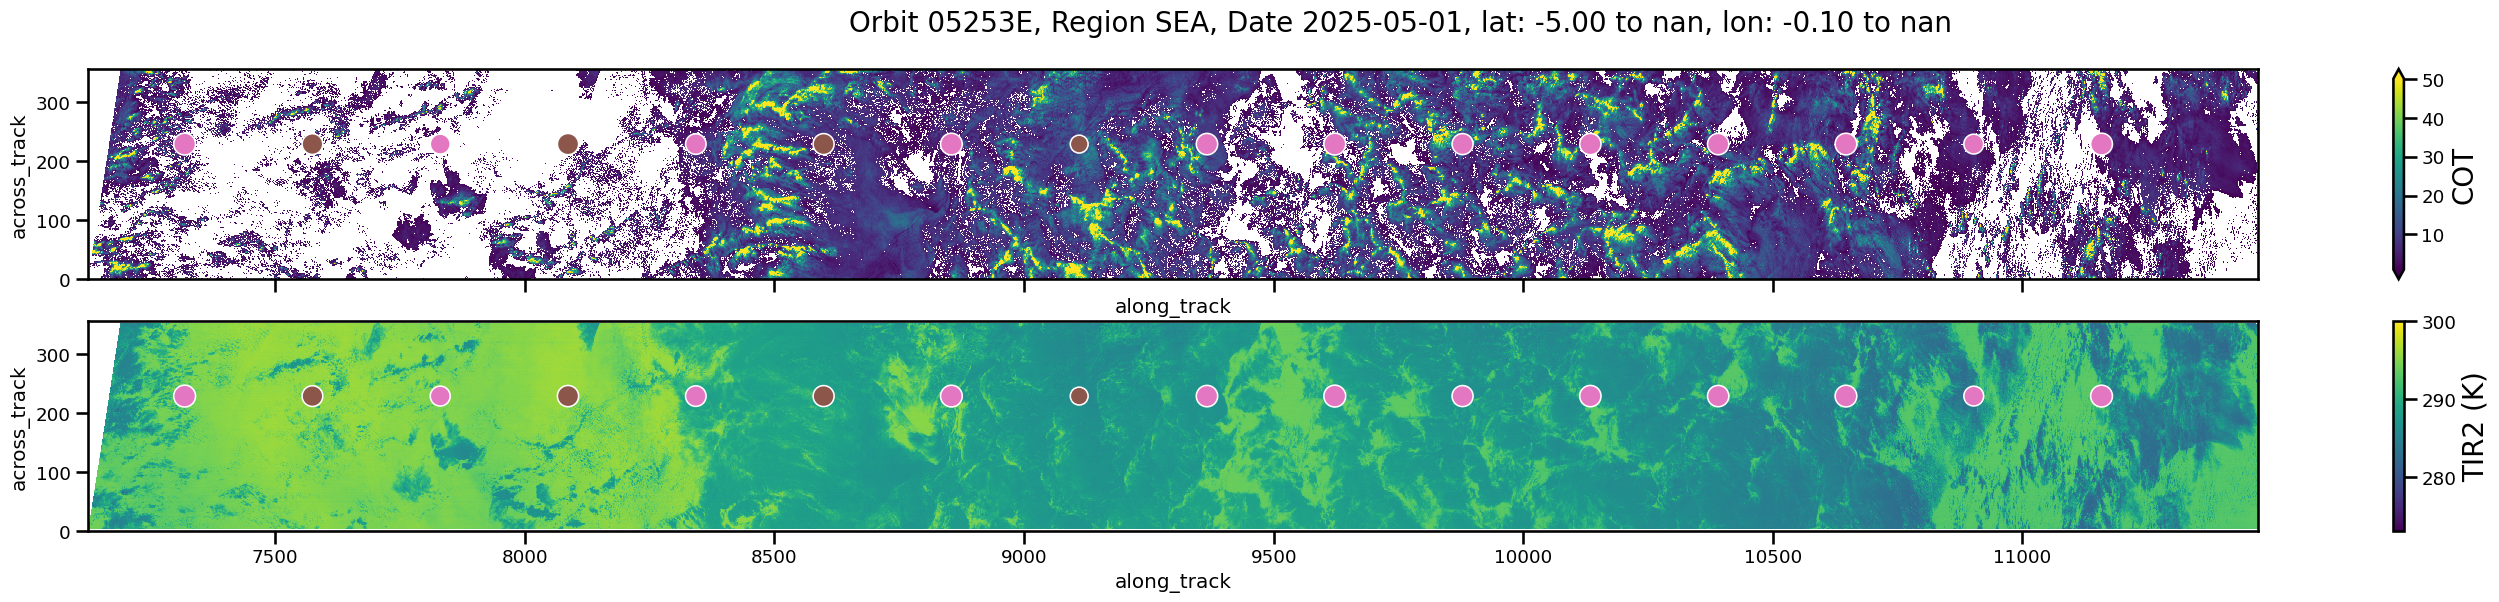

In [4]:
reload(run_judge)
run_judge.main()

In [ ]:
import pandas as pd
pd.read_csv('/home/jmayer/ACI_research/Code/resources/judge_results.csv')

,along_track_values,latitude,longitude,time,cats,cert,orbit
0,7328.5,-5.623466,2.556024,2025-07-01 13:44:26.787088064,4,0.623347,06202E
1,7584.5,-6.667667,2.359902,2025-07-01 13:44:42.915215104,0,0.756681,06202E
2,7840.5,-7.711763,2.163399,2025-07-01 13:44:59.043348992,0,0.499542,06202E
3,8096.5,-8.755718,1.966402,2025-07-01 13:45:15.171477056,0,0.499257,06202E
4,8352.5,-9.799482,1.768789,2025-07-01 13:45:31.299603968,0,0.496071,06202E
5,8608.5,-10.843030,1.570021,2025-07-01 13:45:47.427730944,0,0.987434,06202E
6,8864.5,-11.886424,1.370378,2025-07-01 13:46:03.555857920,0,0.905962,06202E
7,9120.5,-12.929633,1.170179,2025-07-01 13:46:19.683985984,0,0.930533,06202E
8,9376.5,-13.972663,0.969090,2025-07-01 13:46:35.812113088,0,0.518363,06202E
9,9632.5,-15.015502,0.766997,2025-07-01 13:46:51.940240128,3,0.986087,06202E


In [2]:
import judge
import pandas as pd
import os
import sys
from run_judge import trim_to_stcu_region
from importlib import reload
sys.path.append('./../../../ectools/')
from ectools import ecio

<module 'mytorchutils' from '/home/jmayer/ACI_research/Code/causal_aci/src_judge/mytorchutils.py'>

In [ ]:
import glob
orbit = '06311E'
region = 'SEA'
month = '07'
day = '08'
year = '2025'

MCOP_filename = f'/home/jmayer/Object_Data/MSI_COP_2A/{year}/{month}/{day}/*{orbit}.h5'
MRGR_filename = f'/home/jmayer/Object_Data/MSI_RGR_1C/{year}/{month}/{day}/*{orbit}.h5'
ACMCAP_filename = f'/home/jmayer/Object_Data/ACM_CAP_2B/{year}/{month}/{day}/*{orbit}.h5'

In [5]:
import glob
orbit = '05286E'
region = 'NEA'
month = '05'
day = '03'
year = '2025'

MCOP_filename = f'/home/jmayer/Object_Data/MSI_COP_2A/{year}/{month}/{day}/*{orbit}.h5'
MRGR_filename = f'/home/jmayer/Object_Data/MSI_RGR_1C/{year}/{month}/{day}/*{orbit}.h5'
ACMCAP_filename = f'/home/jmayer/Object_Data/ACM_CAP_2B/{year}/{month}/{day}/*{orbit}.h5'

In [6]:
MCOP_file = glob.glob(MCOP_filename)[0]
MRGR_file = glob.glob(MRGR_filename)[0]
ACMCAP_file = glob.glob(ACMCAP_filename)[0]

MCOP = ecio.load_MCOP(MCOP_file)
MRGR = ecio.load_MRGR(MRGR_file)
MCOP = trim_to_stcu_region(MCOP, region, orbit[-1])
MRGR = trim_to_stcu_region(MRGR, region, orbit[-1])
MRGR = MRGR.where(MRGR.TIR1 < 1e30)

Selecting frame from 435 to 11473
Selecting frame from 435 to 11473


In [7]:
MRGR

<xarray.Dataset> Size: 202MB
Dimensions:                      (along_track: 2050, across_track: 357,
                                  band: 7, VNS_band: 4)
Coordinates:
  * band                         (band) <U5 140B 'VIS' 'VNIR' ... 'TIR2' 'TIR3'
    latitude                     (along_track, across_track) float64 6MB 22.2...
    longitude                    (along_track, across_track) float64 6MB -38....
  * along_track                  (along_track) int64 16kB 435 436 ... 2483 2484
Dimensions without coordinates: across_track, VNS_band
Data variables: (12/27)
    time                         (along_track, across_track) datetime64[ns] 6MB ...
    state_vector_quality_status  (along_track, across_track) float64 6MB nan ...
    time_synchronisation_status  (along_track, across_track) float32 3MB nan ...
    ccdb_redundancy_flag         (along_track, across_track) float32 3MB nan ...
    pixel_values                 (band, along_track, across_track) float32 20MB ...
    pixel_values_uncertainty     (band, along_track, across_track) float32 20MB ...
    ...                           ...
    NIR                          (along_track, across_track) float32 3MB nan ...
    SWIR1                        (along_track, across_track) float32 3MB nan ...
    SWIR2                        (along_track, across_track) float32 3MB nan ...
    TIR1                         (along_track, across_track) float32 3MB nan ...
    TIR2                         (along_track, across_track) float32 3MB nan ...
    TIR3                         (along_track, across_track) float32 3MB nan ...

In [13]:
reload(judge.mytorchutils)
print('Running judge...')
cats, cert, scene_midpoints = judge.judge_MSI(MCOP, MRGR, debugging=False)
print('\tDone!')

Running judge...
(0,) 0
(0,)
	Done!


In [41]:
scene_midpoints

{'along_track_mid': [7322.5,
  7578.5,
  7834.5,
  8090.5,
  8346.5,
  8602.5,
  8858.5,
  9114.5,
  9370.5,
  9626.5,
  9882.5,
  10138.5,
  10394.5,
  10650.5,
  10906.5,
  11162.5],
 'time_mid': [np.datetime64('2025-07-08T13:51:31.361348928'),
  np.datetime64('2025-07-08T13:51:47.489476992'),
  np.datetime64('2025-07-08T13:52:03.617604992'),
  np.datetime64('2025-07-08T13:52:19.745731968'),
  np.datetime64('2025-07-08T13:52:35.873859968'),
  np.datetime64('2025-07-08T13:52:52.001990528'),
  np.datetime64('2025-07-08T13:53:08.130121920'),
  np.datetime64('2025-07-08T13:53:24.258248960'),
  np.datetime64('2025-07-08T13:53:40.386377088'),
  np.datetime64('2025-07-08T13:53:56.514505088'),
  np.datetime64('2025-07-08T13:54:12.642632000'),
  np.datetime64('2025-07-08T13:54:28.770760000'),
  np.datetime64('2025-07-08T13:54:44.898887936'),
  np.datetime64('2025-07-08T13:55:01.027018496'),
  np.datetime64('2025-07-08T13:55:17.155149888'),
  np.datetime64('2025-07-08T13:55:33.283276992')],
 '

In [11]:
df = pd.DataFrame(scene_midpoints)
df['cats'] = cats
df['cert'] = cert
df['orbit'] = orbit

ValueError: If using all scalar values, you must pass an index

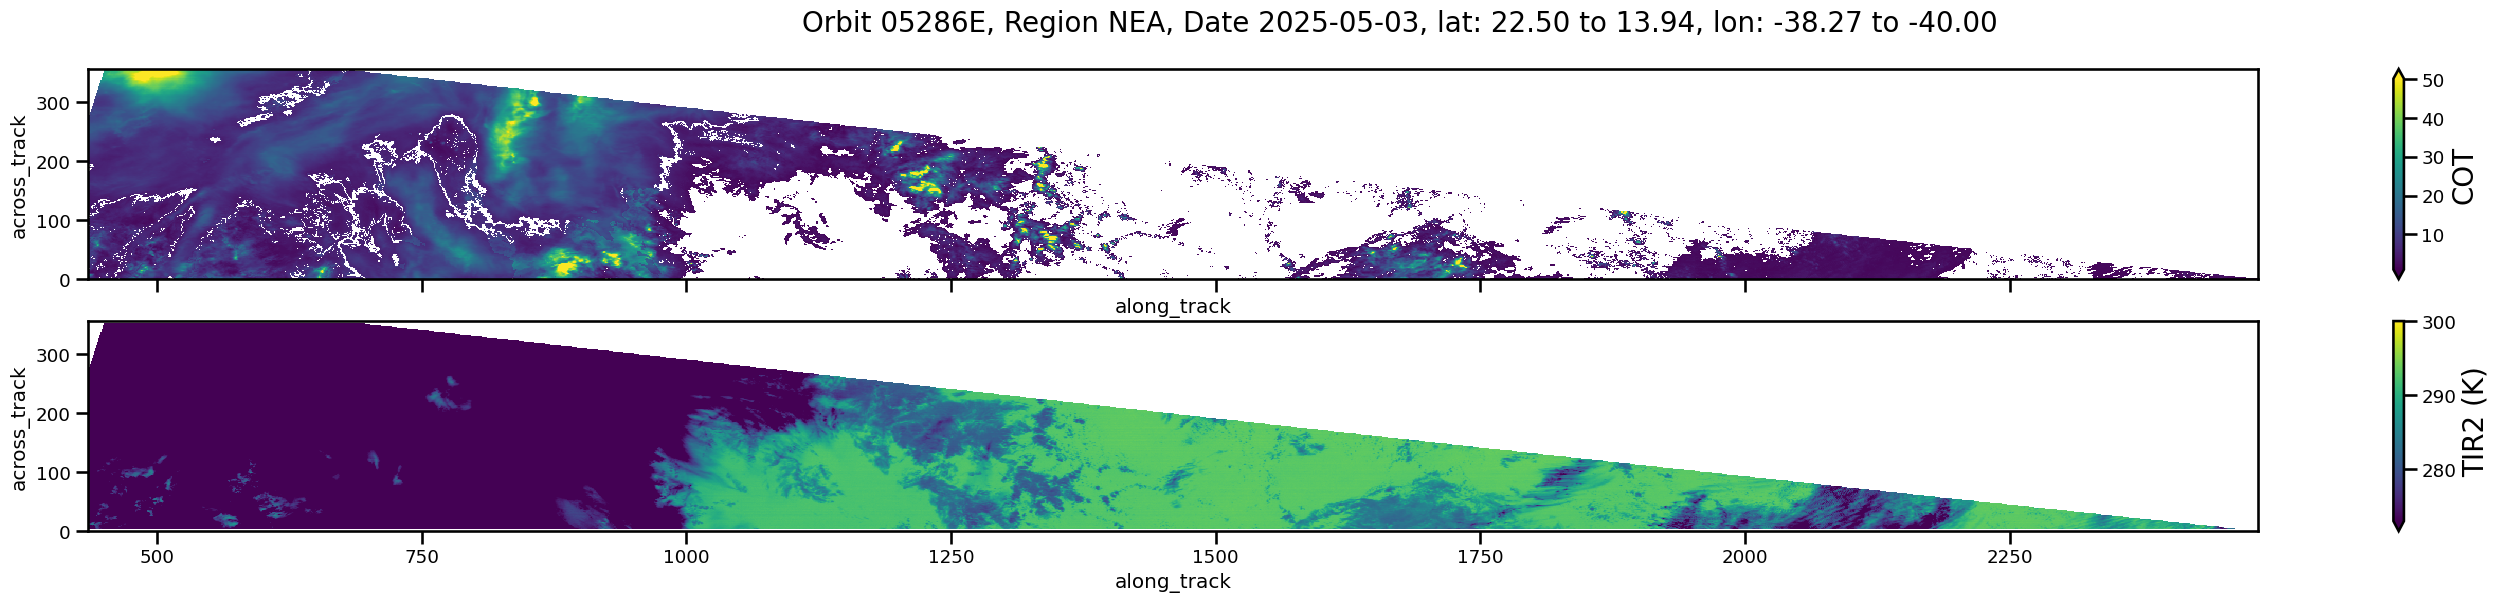

In [12]:
from run_judge import plot_judge_results
plot_judge_results(MCOP, MRGR, df, orbit, region, year, month, day, save_to=None)

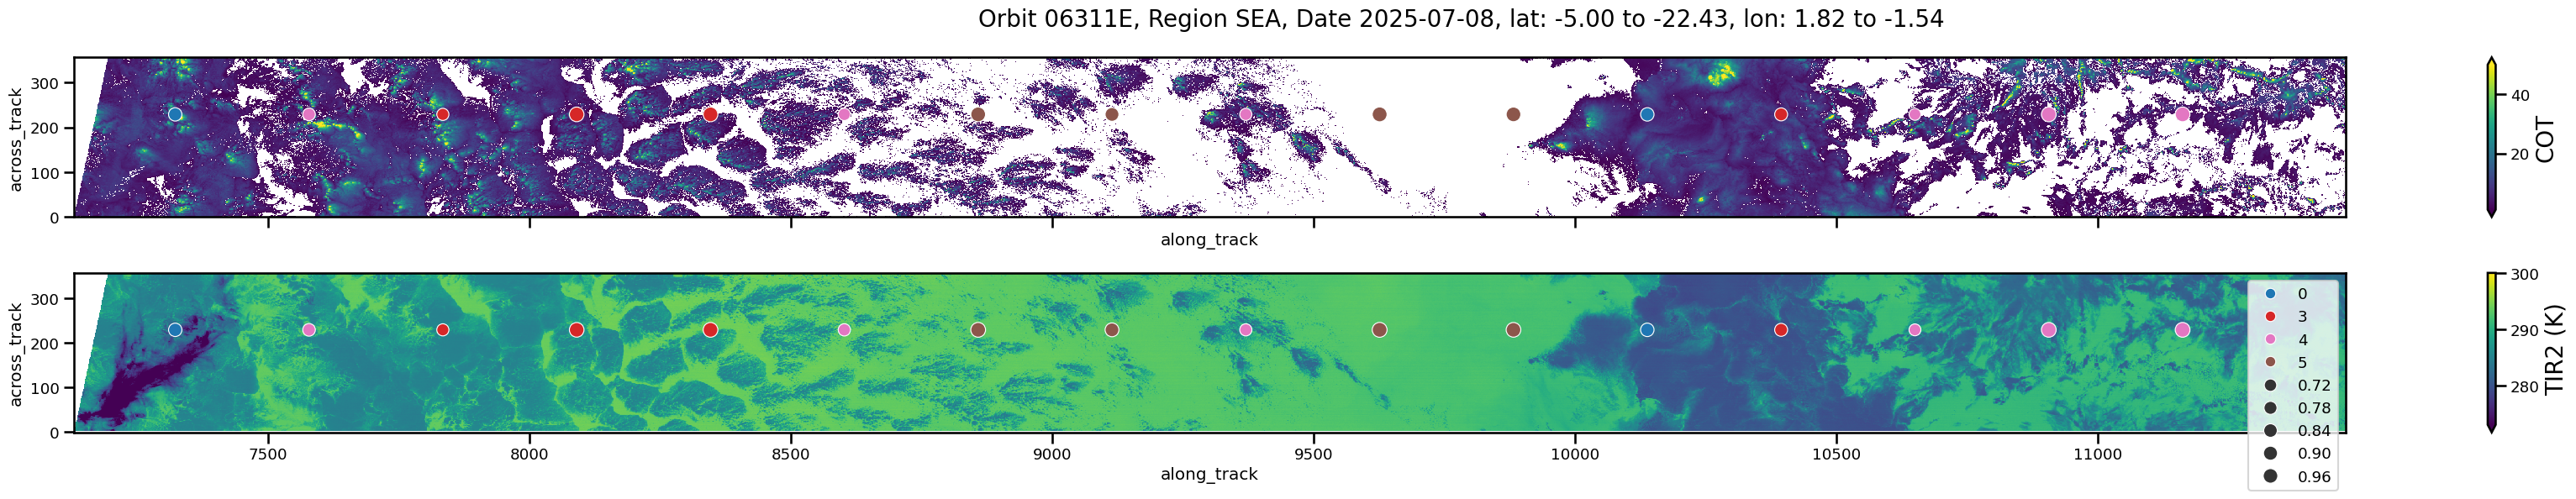

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_context('talk', font_scale=0.8)
fig, axs = plt.subplots(2, 1, figsize=(35,6), sharex=True)
plt.suptitle(
    f'Orbit {orbit}, Region {region}, Date 2025-{month}-{day}, '
    f'lat: {np.nanmax(MCOP.latitude.values[0,:]):.2f} to {np.nanmax(MCOP.latitude.values[-1,:]):.2f}, '
    f'lon: {np.nanmax(MCOP.longitude.values[0,:]):.2f} to {np.nanmax(MCOP.longitude.values[-1,:]):.2f}',
    fontsize = 20
)
MCOP.cloud_optical_thickness.T.plot(ax=axs[0], vmin=1, vmax=50)
cbar = axs[0].collections[0].colorbar
cbar.set_label('COT', fontsize=20)

MRGR.TIR2.T.plot(ax=axs[1], vmin=273, vmax=300)
cbar = axs[1].collections[0].colorbar
cbar.set_label('TIR2 (K)', fontsize=20)

hue = np.where(df.ice_flag == 1, 6, df.cats)
colors = ['#1f77b4', '#2ca02c', '#ff7f0e',  '#d62728', '#e377c2', '#8c564b', 'white'] # last color is for ice
palette = {0: colors[0], 1: colors[1], 2: colors[2], 3: colors[3], 4: colors[4], 5: colors[5], 6: colors[6]}
for i in [0,1]:
    legend = True if i == 1 else False
    scatter = sns.scatterplot(ax=axs[i], x = df.along_track_mid, y=MRGR.dims['across_track'] - 128, hue=hue, size=df.cert, size_norm=(0.3,1),
                    marker='o', palette=palette, legend=legend)
    if legend and scatter.legend_ is not None:
        scatter.legend_.set_title('')
fig.tight_layout()

In [15]:
scene_midpoints['cloud_cover']

[0.95703125,
 0.7564697265625,
 0.85028076171875,
 0.79327392578125,
 0.6329345703125,
 0.47064208984375,
 0.289306640625,
 0.29840087890625,
 0.36566162109375,
 0.04974365234375,
 0.09954833984375,
 0.85247802734375,
 0.9298095703125,
 0.4798583984375,
 0.53857421875,
 0.44610595703125]

In [10]:
stratus_regions = {
    'SEA': {'lat': (-25, -5), 'lon': (-5, 15)},    # South East Atlantic
    'NEA': {'lat': (10, 30), 'lon': (-40, -20)},   # North East Atlantic
    'SEP': {'lat': (-25, -5), 'lon': (-95, -75)},  # South East Pacific
    'NEP': {'lat': (15, 35), 'lon': (-135, -115)}, # North East Pacific
}
ACMCAP = ecio.load_ACMCAP(ACMCAP_file)
ACMCAP = ACMCAP.where((ACMCAP['latitude'] >= stratus_regions[region]['lat'][0]) & (ACMCAP['latitude'] <= stratus_regions[region]['lat'][1]), drop=True)

Selecting frame from 8 to 4876


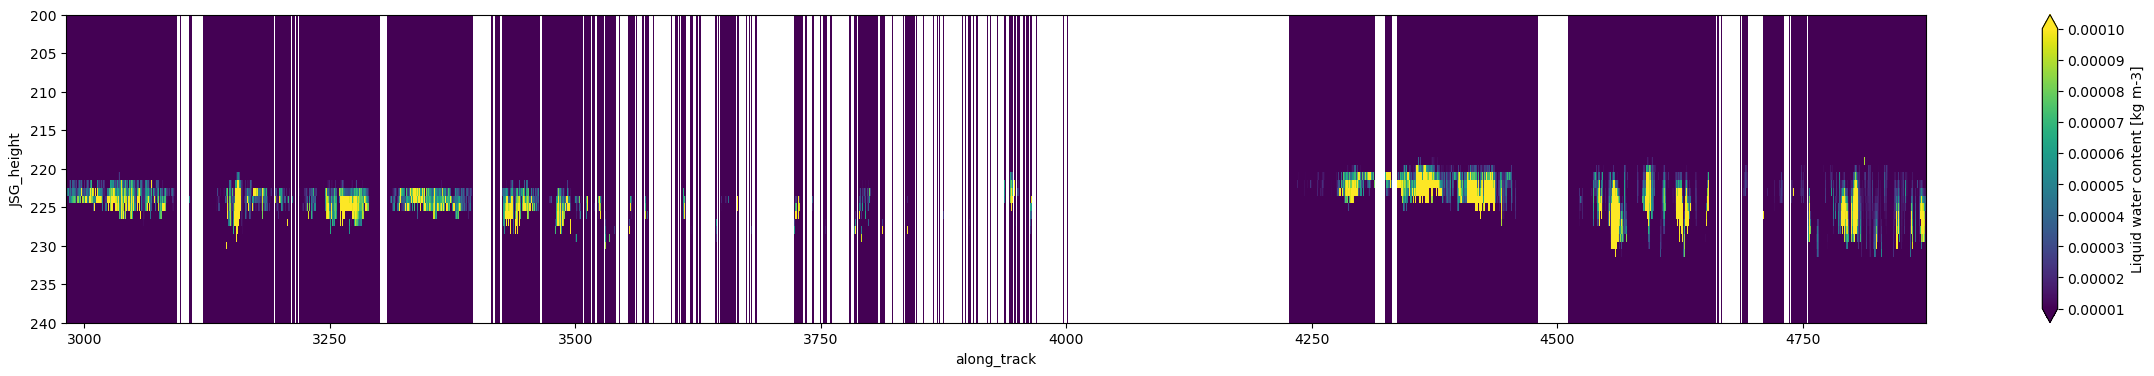

In [11]:
ACMCAP.liquid_water_content.T.plot(figsize=(30,4), vmin=1e-5, vmax=1e-4, ylim=(240,200))

In [28]:
i = 1
ACMCAP_i = ACMCAP.where((ACMCAP.latitude >= scene_midpoints['lat_min'][i]) & (ACMCAP.latitude <= scene_midpoints['lat_max'][i]), drop=True)

In [18]:
import pandas as pd
i = 5
ACMCAP_i = ACMCAP.where((ACMCAP.time >= pd.to_datetime(scene_midpoints['time_mid'][i])) & (ACMCAP.time <= pd.to_datetime(scene_midpoints['time_mid'][i+1])), drop=True)

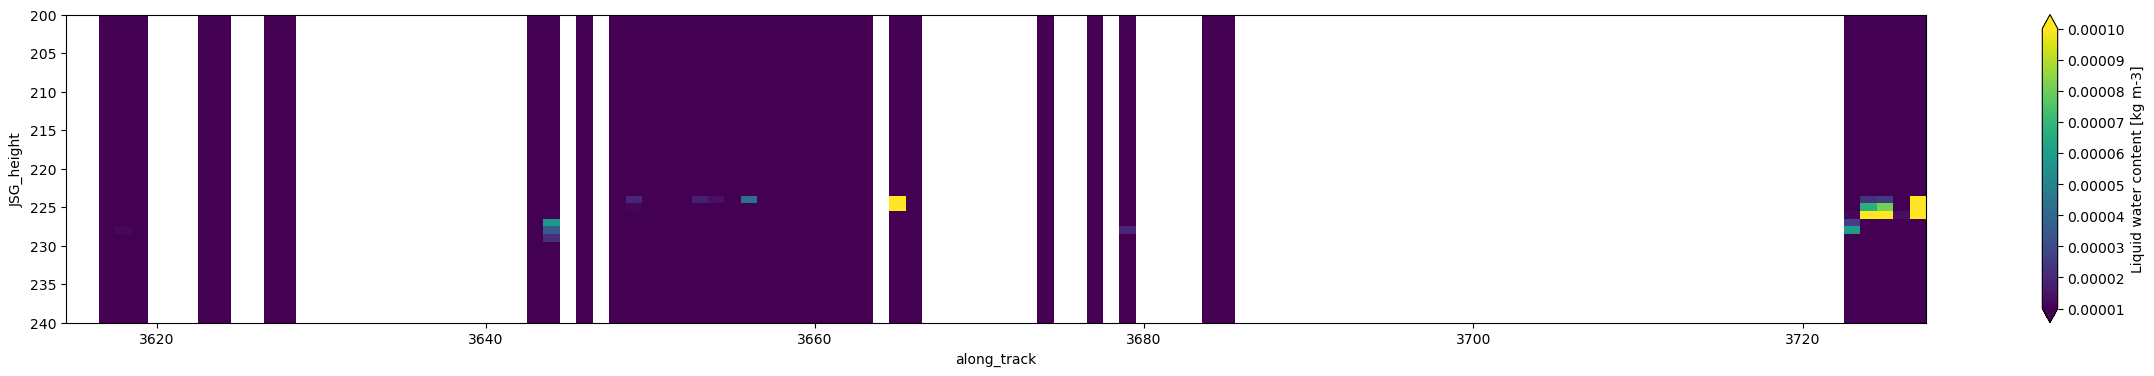

In [19]:
ACMCAP_i.liquid_water_content.T.plot(figsize=(30,4), vmin=1e-5, vmax=1e-4, ylim=(240,200))

In [29]:
ACMCAP_i

<xarray.Dataset> Size: 13MB
Dimensions:                                                         (
                                                                     along_track: 112,
                                                                     JSG_height: 242,
                                                                     MSI_longwave_channel: 3,
                                                                     MSI_shortwave_channel: 1)
Coordinates:
  * along_track                                                     (along_track) int64 896B ...
Dimensions without coordinates: JSG_height, MSI_longwave_channel,
                                MSI_shortwave_channel
Data variables: (12/192)
    time                                                            (along_track) datetime64[ns] 896B ...
    latitude                                                        (along_track) float64 896B ...
    longitude                                                       (along_track) float64 896B ...
    height                                                          (along_track, JSG_height) float32 108kB ...
    geoid_offset                                                    (along_track) float32 448B ...
    elevation                                                       (along_track) float32 448B ...
    ...                                                              ...
    MSI_shortwave_observation_variable_count                        (along_track) float64 896B ...
    MSI_shortwave_cost_function                                     (along_track) float32 448B ...
    MSI_shortwave_wavelength                                        (MSI_shortwave_channel, along_track) float32 448B ...
    MSI_shortwave_albedo_forward                                    (along_track, MSI_shortwave_channel) float32 448B ...
    MSI_shortwave_albedo                                            (along_track, MSI_shortwave_channel) float32 448B ...
    MSI_shortwave_albedo_assimilation_status                        (along_track) float32 448B ...

In [27]:
for i in range(len(scene_midpoints['time_mid'])-1):
    ACMCAP_i = ACMCAP.where((ACMCAP.latitude >= scene_midpoints['lat_min'][i]) & (ACMCAP.latitude <= scene_midpoints['lat_max'][i]), drop=True)
    print(len(ACMCAP_i.along_track))
    ACMCAP_i = ACMCAP.where((ACMCAP.time >= pd.to_datetime(scene_midpoints['time_mid'][i])) & (ACMCAP.time <= pd.to_datetime(scene_midpoints['time_mid'][i+1])), drop=True)
    print(len(ACMCAP_i.along_track))
    print()

113
113

112
113

113
113

113
113

113
113

113
113

113
113

113
112

113
113

112
113

113
113

113
113

113
113

113
113

113
113

